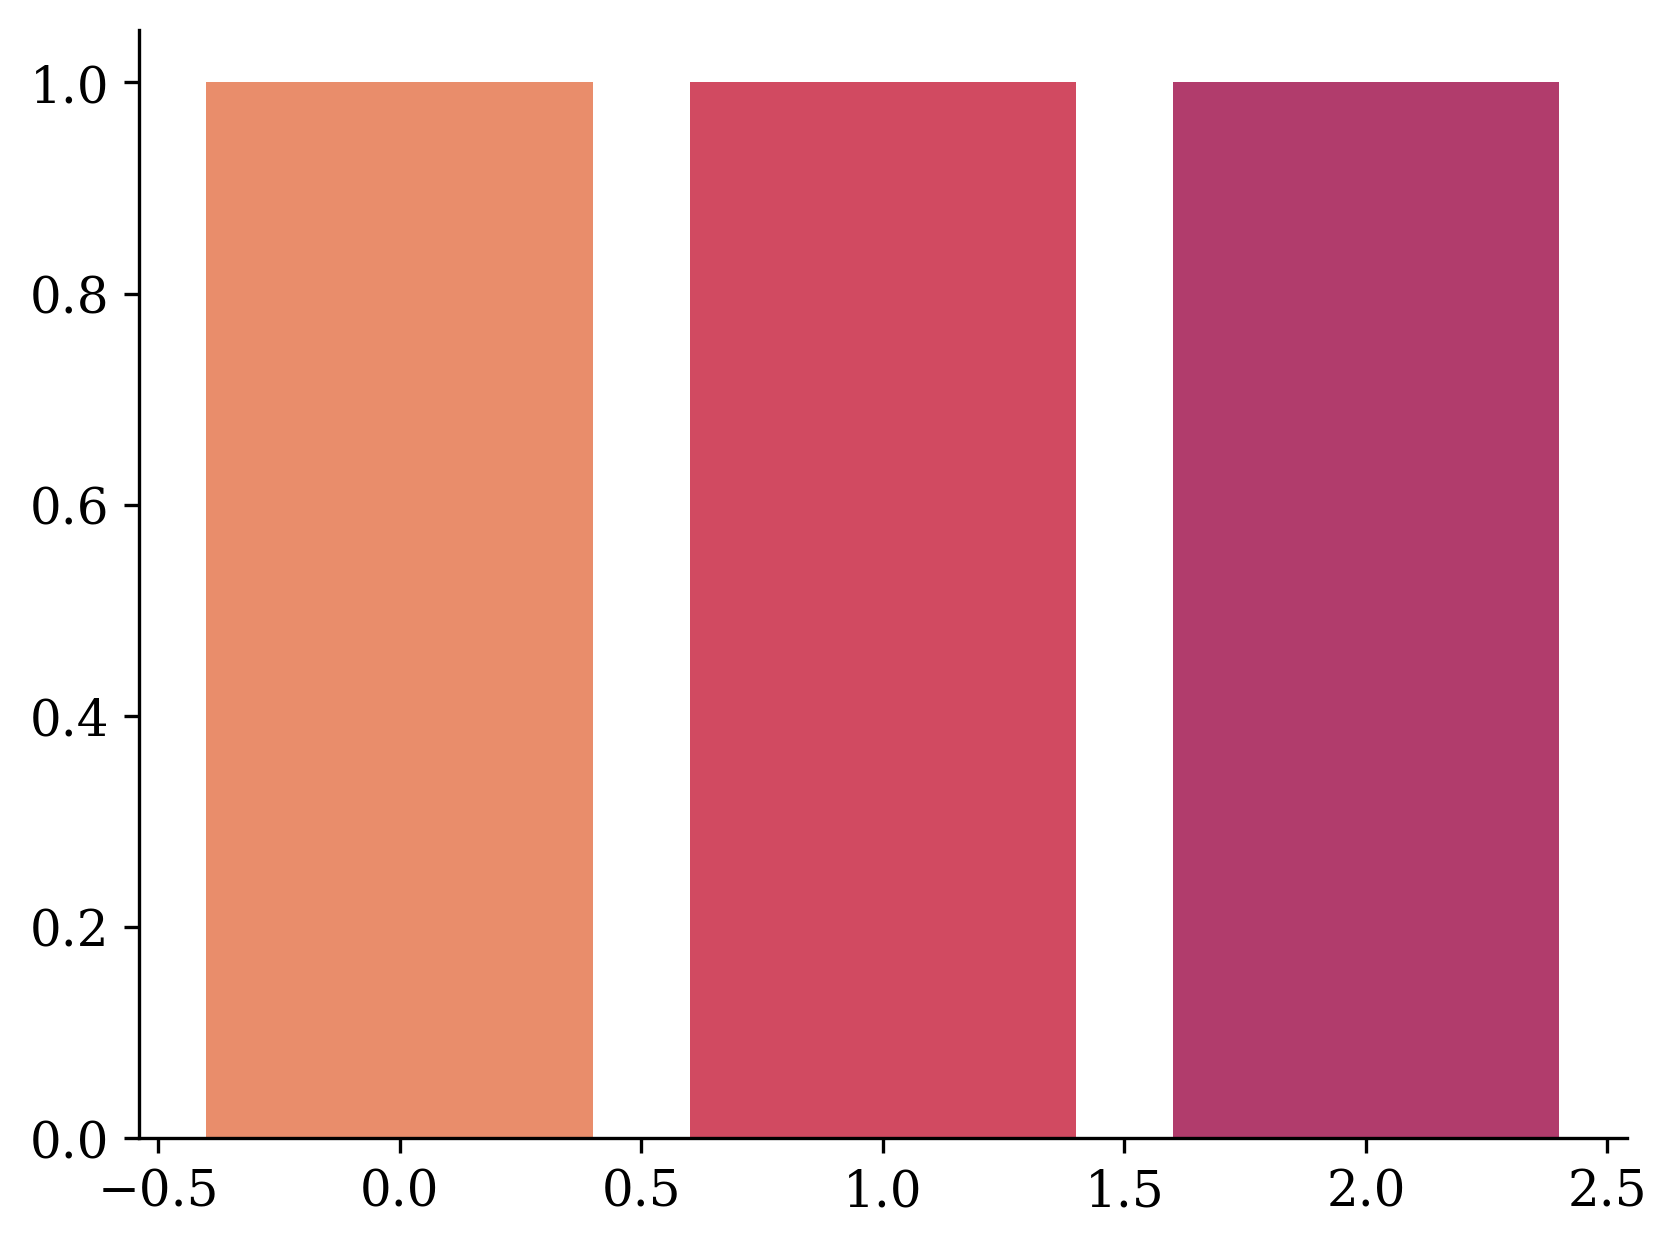

In [11]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import seaborn as sns
 
# Load data
with open("original_results.json") as f:
    original = json.load(f)
with open("my_results_2.json") as f:
    tantgen_3x = json.load(f)
with open("my_results_5.json") as f:
    tantgen_6x = json.load(f)
with open("others_results_2.json") as f:
    tm_3x = json.load(f)
with open("others_results_5.json") as f:
    tm_6x = json.load(f)
 
# Data
labels = ["3x limit", "6x limit"]
original_asr = [original["ASR"], original["ASR"]]
tm_asr       = [tm_3x["ASR"],      tm_6x["ASR"]]
tantgen_asr  = [tantgen_3x["ASR"], tantgen_6x["ASR"]]
 
x = np.arange(len(labels))
 
# Style
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "lines.linewidth": 1,
    "axes.linewidth": 0.8,
    # ???
    "axes.spines.top": False,
    "axes.spines.right": False,
    # 
    "figure.dpi": 300
})

palette = sns.color_palette("flare") #("flare") #("Set2") #("husl", 9) #("pastel")

palette = {
    "Original": palette[0],
    "TrafficManipulator": palette[2],
    "TANTGen": palette[3],
}

# show palette colors
for i, color in enumerate(palette.values()):
    plt.bar(i, 1, color=color)



Saved.


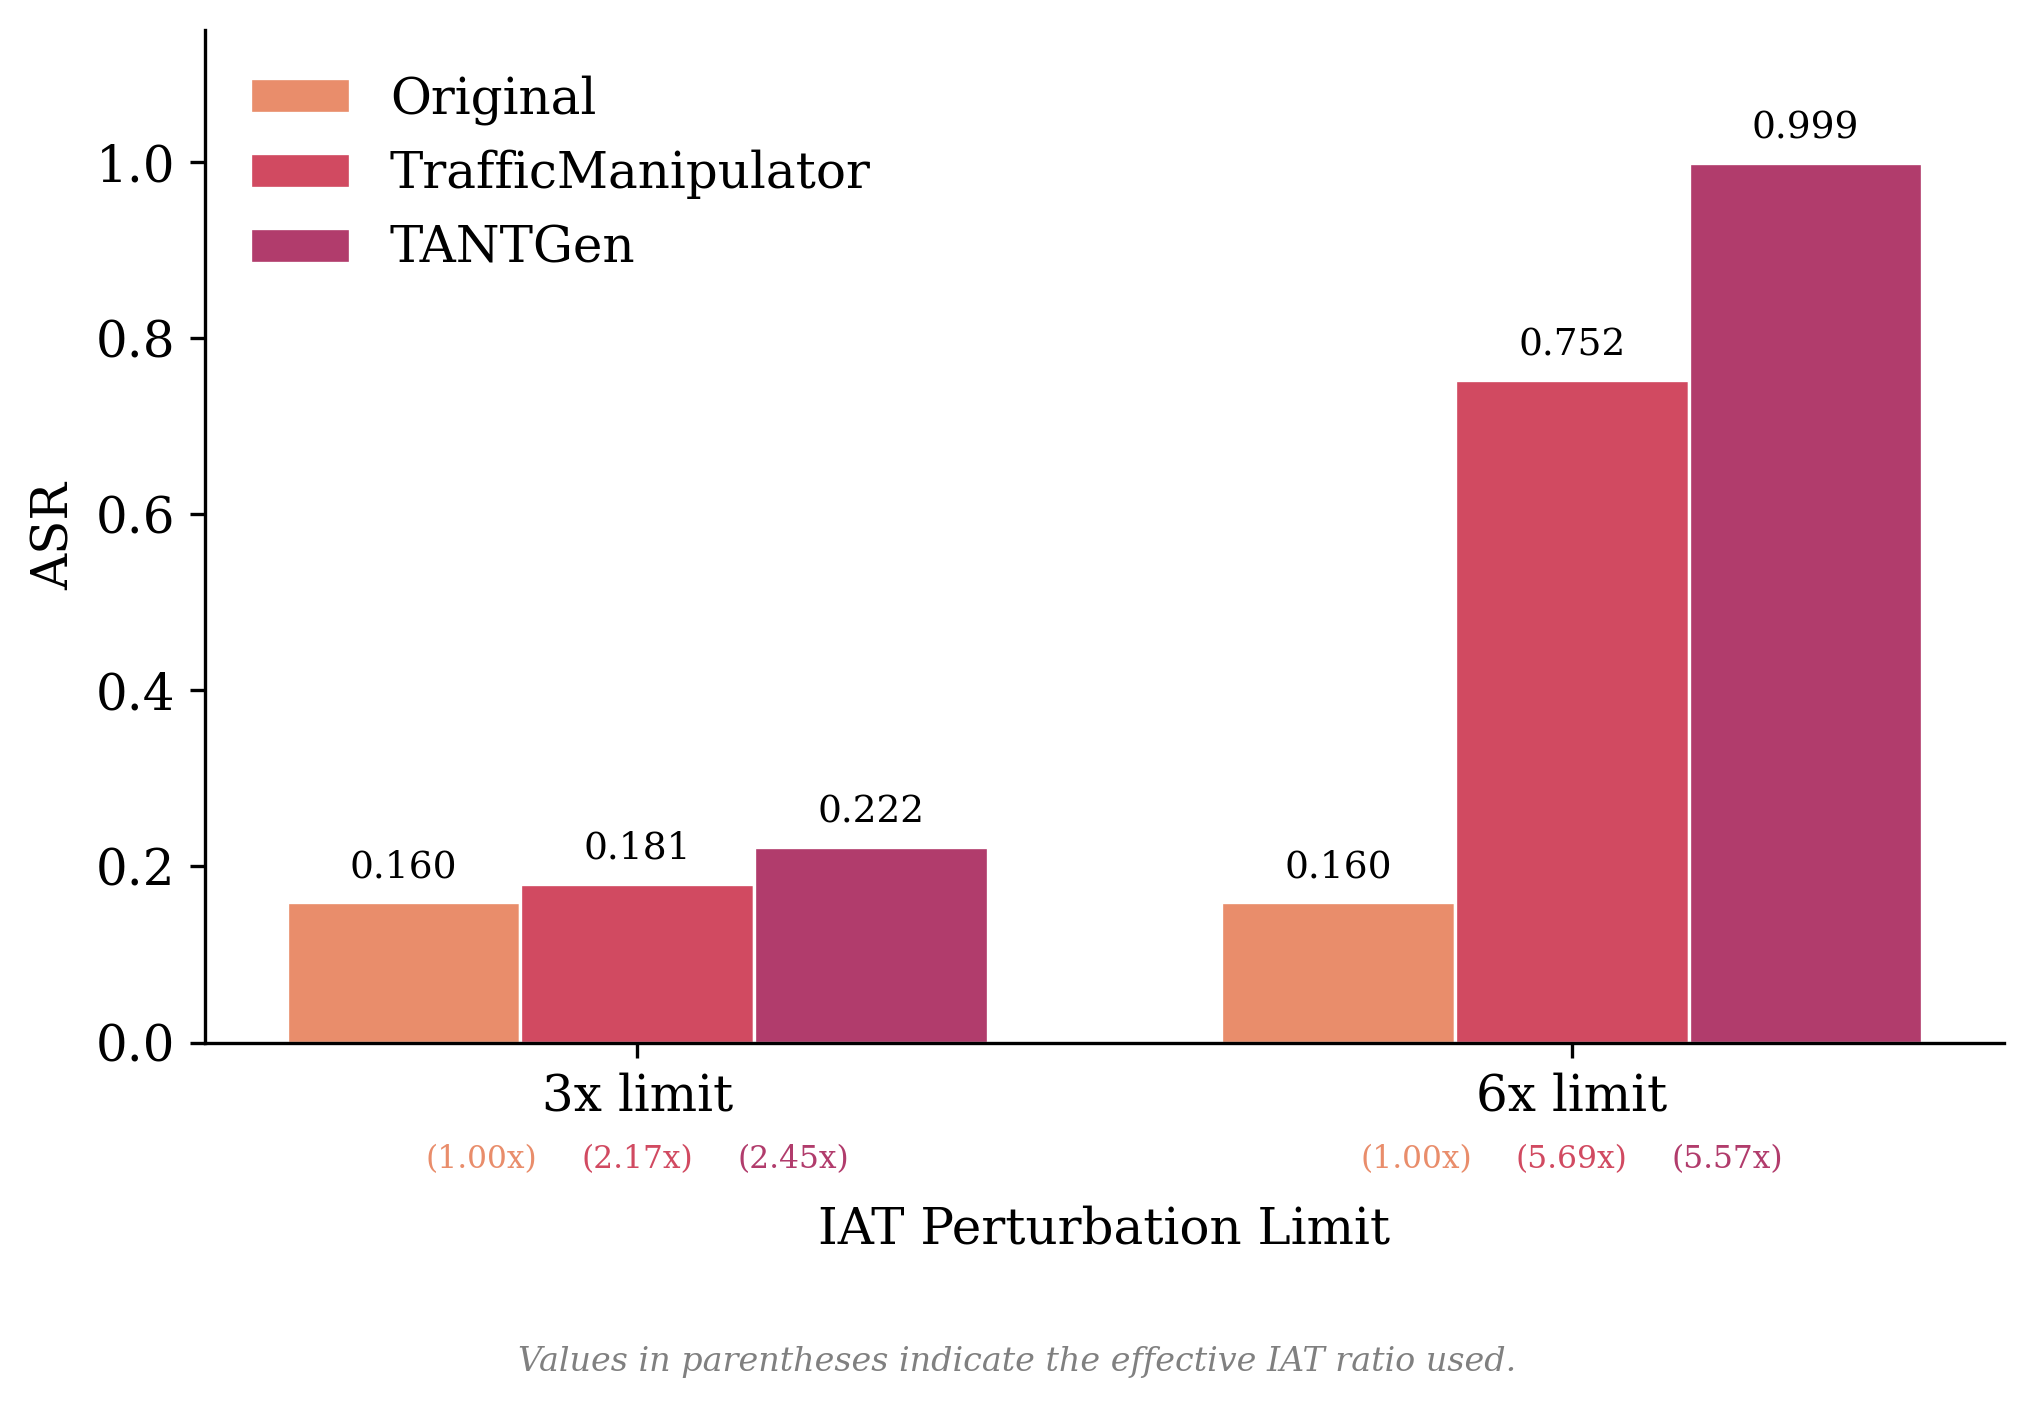

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))

width = 0.25

bars0 = ax.bar(x - width, [v if v is not None else 0 for v in original_asr], width,
               label="Original", color=palette["Original"], edgecolor="white", linewidth=0.8)
bars1 = ax.bar(x,  [v if v is not None else 0 for v in tm_asr], width,
               label="TrafficManipulator", color=palette["TrafficManipulator"], edgecolor="white", linewidth=0.8)
bars2 = ax.bar(x + width,          [v if v is not None else 0 for v in tantgen_asr], width,
               label="TANTGen", color=palette["TANTGen"], edgecolor="white", linewidth=0.8)
 
for bars, asr_list in [(bars0, original_asr), (bars1, tm_asr), (bars2, tantgen_asr)]:
    for bar, val in zip(bars, asr_list):
        if val is None:
            continue
        ax.annotate(f"{val:.3f}",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)
 
# Effective ratio annotations below x-axis labels
ratio_original = [f"({original['Rate']:.2f}x)"] * len(labels)
ratio_tm      = [f"({tm_3x['Rate']:.2f}x)",      f"({tm_6x['Rate']:.2f}x)"]
ratio_tantgen = [f"({tantgen_3x['Ratio']:.2f}x)", f"({tantgen_6x['Ratio']:.2f}x)"]

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel("ASR")
ax.set_xlabel("IAT Perturbation Limit", labelpad=20)
#ax.set_title("TANTGen vs TrafficManipulator — Mirai Botnet (Kitsune)")
ax.legend(frameon=False)
 
# Add effective ratio as secondary annotation under each group
for i, xi in enumerate(x):
    ax.text(xi - width*2/3, -0.10, ratio_original[i],
            ha="center", va="top", fontsize=7.5, 
            color=palette["Original"], #"#E8956D",
            transform=ax.get_xaxis_transform())
    ax.text(xi, -0.10, ratio_tm[i],
            ha="center", va="top", fontsize=7.5, 
            color=palette["TrafficManipulator"], #"#E8956D",
            transform=ax.get_xaxis_transform())
    ax.text(xi + width*2/3, -0.10, ratio_tantgen[i],
            ha="center", va="top", fontsize=7.5,
            color=palette["TANTGen"], #"#5B8DB8",
            transform=ax.get_xaxis_transform())
 
# Effective ratio legend note
fig.text(0.5, -0.04,
         "Values in parentheses indicate the effective IAT ratio used.",
         ha="center", fontsize=8, style="italic", color="gray")
 
plt.tight_layout()
plt.savefig("tantgen_vs_tm_mirai.png",
            bbox_inches="tight", dpi=300)
print("Saved.")